# 1. Construct KNN classification model

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load dataset
df = pd.read_csv('voice.csv')

# Features dan target
features = [
    'meanfun',
    'IQR',
    'Q25',
    'sd',
    'sp.ent',
    'mode',
    'sfm',
    'meanfreq'
]

X = df[features]
y = df['label']

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# KNN model
model = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])

# Training
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Evaluation
accuracy = accuracy_score(y_test, y_pred)

print("Features yang digunakan:")
print(features)

print("\nAccuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Features yang digunakan:
['meanfun', 'IQR', 'Q25', 'sd', 'sp.ent', 'mode', 'sfm', 'meanfreq']

Accuracy: 0.9826498422712934

Classification Report:
              precision    recall  f1-score   support

      female       0.99      0.97      0.98       317
        male       0.98      0.99      0.98       317

    accuracy                           0.98       634
   macro avg       0.98      0.98      0.98       634
weighted avg       0.98      0.98      0.98       634


Confusion Matrix:
[[309   8]
 [  3 314]]


A K-Nearest Neighbors (KNN) classification model was constructed to classify voice samples into male and female classes. The dataset was divided into training and testing sets using an 80:20 ratio. Before applying KNN, the features were standardized using StandardScaler because KNN relies on distance calculations. The model used the selected eight features and k=5.

# 2. Eksperimen fitur

In [2]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Ranking fitur berdasarkan hasil eksperimen
feature_order = [
    'meanfun',
    'IQR',
    'Q25',
    'sd',
    'sp.ent',
    'mode',
    'sfm',
    'meanfreq',
    'centroid',
    'mindom',
    'maxdom',
    'median',
    'skew',
    'dfrange',
    'kurt',
    'meandom',
    'maxfun',
    'minfun',
    'Q75',
    'modindx'
]

results = []

for n in range(1, len(feature_order) + 1):

    selected_features = feature_order[:n]

    model = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=5))
    ])

    scores = cross_val_score(
        model,
        df[selected_features],
        y,
        cv=cv,
        scoring='accuracy'
    )

    results.append({
        'Number of Features': n,
        'Features': selected_features,
        'Accuracy': scores.mean()
    })

results_df = pd.DataFrame(results)

print(results_df[['Number of Features', 'Accuracy']])

    Number of Features  Accuracy
0                    1  0.947284
1                    2  0.968751
2                    3  0.973485
3                    4  0.978534
4                    5  0.978532
5                    6  0.978850
6                    7  0.981061
7                    8  0.982008
8                    9  0.981377
9                   10  0.979481
10                  11  0.978536
11                  12  0.979483
12                  13  0.978536
13                  14  0.977272
14                  15  0.977273
15                  16  0.976956
16                  17  0.975378
17                  18  0.976958
18                  19  0.976641
19                  20  0.975062


In [3]:
best_result = results_df.loc[
    results_df['Accuracy'].idxmax()
]

print("Best number of features:",
      best_result['Number of Features'])

print("Best features:")
print(best_result['Features'])

print("Best accuracy:",
      best_result['Accuracy'])

Best number of features: 8
Best features:
['meanfun', 'IQR', 'Q25', 'sd', 'sp.ent', 'mode', 'sfm', 'meanfreq']
Best accuracy: 0.9820079636800374


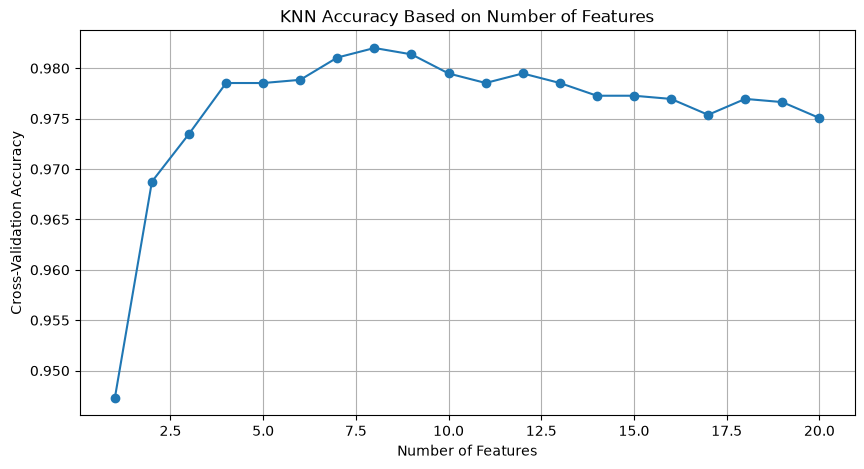

In [4]:
plt.figure(figsize=(10, 5))

plt.plot(
    results_df['Number of Features'],
    results_df['Accuracy'],
    marker='o'
)

plt.xlabel('Number of Features')
plt.ylabel('Cross-Validation Accuracy')
plt.title('KNN Accuracy Based on Number of Features')

plt.grid()
plt.show()

Feature experiments were conducted by gradually adding features based on their classification performance. The best result was obtained using eight features: meanfun, IQR, Q25, sd, sp.ent, mode, sfm, and meanfreq. Using these features, the KNN model achieved approximately 98.20% accuracy using 5-fold cross-validation. The meanfun feature was particularly informative, achieving approximately 94.73% accuracy even when used individually.

# 3. Menentukan nilai k terbaik

In [5]:
best_features = [
    'meanfun',
    'IQR',
    'Q25',
    'sd',
    'sp.ent',
    'mode',
    'sfm',
    'meanfreq'
]

k_results = []

for k in range(1, 31):

    model = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])

    scores = cross_val_score(
        model,
        df[best_features],
        y,
        cv=cv,
        scoring='accuracy'
    )

    k_results.append({
        'k': k,
        'accuracy': scores.mean()
    })

k_results_df = pd.DataFrame(k_results)

print(k_results_df)

     k  accuracy
0    1  0.977269
1    2  0.979483
2    3  0.982007
3    4  0.981693
4    5  0.982008
5    6  0.981378
6    7  0.980745
7    8  0.981377
8    9  0.979798
9   10  0.980429
10  11  0.979482
11  12  0.979166
12  13  0.978220
13  14  0.974433
14  15  0.973803
15  16  0.973172
16  17  0.971277
17  18  0.972539
18  19  0.970961
19  20  0.971276
20  21  0.969382
21  22  0.970646
22  23  0.969698
23  24  0.970014
24  25  0.970013
25  26  0.969698
26  27  0.968436
27  28  0.969382
28  29  0.967804
29  30  0.968120


In [6]:
best_k = k_results_df.loc[
    k_results_df['accuracy'].idxmax()
]

print("Best k:", best_k['k'])
print("Best accuracy:", best_k['accuracy'])

Best k: 5.0
Best accuracy: 0.9820079636800374


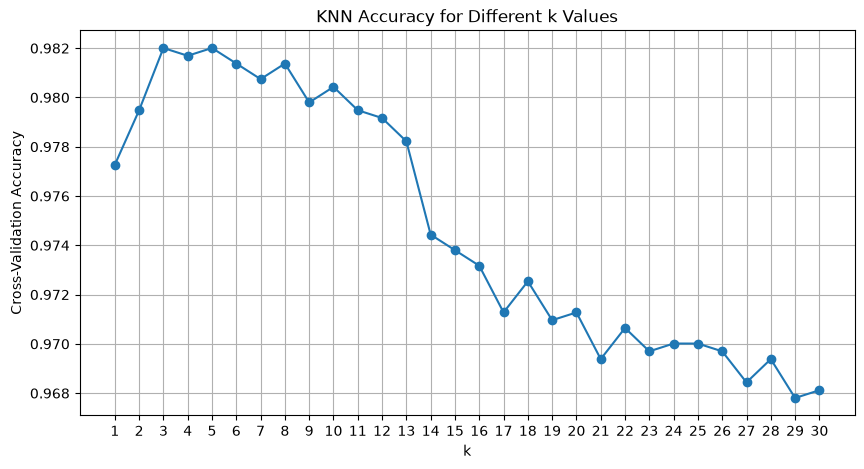

In [7]:
plt.figure(figsize=(10, 5))

plt.plot(
    k_results_df['k'],
    k_results_df['accuracy'],
    marker='o'
)

plt.xlabel('k')
plt.ylabel('Cross-Validation Accuracy')
plt.title('KNN Accuracy for Different k Values')

plt.xticks(range(1, 31))
plt.grid()

plt.show()

Based on the selected eight features, different values of k from 1 to 30 were evaluated using 5-fold cross-validation. The best result was obtained at k=5, with an accuracy of approximately 98.20%. Therefore, k=5 was selected as the optimal value. A very small k can make KNN sensitive to noise, while a larger k can make the decision boundary overly smooth. In this experiment, k=5 provided the best balance between these effects.